In [1]:
import sys; print(sys.executable)

/Users/louisa/lung_project/lung-trajectories/.venv/bin/python3.12


#### Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path = "../data/fev1.dta"
df = pd.read_stata(path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(pd.io.stata.StataReader(path).variable_labels())
df.head(10)


Shape: (1994, 6)
Columns: ['id', 'ht', 'age', 'baseht', 'baseage', 'logfev1']
{'id': '', 'ht': '', 'age': '', 'baseht': '', 'baseage': '', 'logfev1': ''}


,id,ht,age,baseht,baseage,logfev1
0,1.0,1.20,9.341500,1.20,9.3415,0.21511
1,1.0,1.28,10.392900,1.20,9.3415,0.37156
2,1.0,1.33,11.452400,1.20,9.3415,0.48858
3,1.0,1.42,12.460000,1.20,9.3415,0.75142
4,1.0,1.48,13.418200,1.20,9.3415,0.83291
5,1.0,1.50,15.474300,1.20,9.3415,0.89200
6,1.0,1.52,16.372299,1.20,9.3415,0.87129
7,2.0,1.13,6.587300,1.13,6.5873,0.30748
8,2.0,1.19,7.649600,1.13,6.5873,0.35066
9,2.0,1.49,12.739200,1.13,6.5873,0.75612


### Rename and clean

In [3]:
df = df.rename(columns={
    "ht": "height",
    "baseht": "init_height",
    "baseage": "init_age",
    "logfev1": "log_fev1",
})
df["id"] = df["id"].astype(int)
df["fev1"] = np.exp(df["log_fev1"])          # FEV1 in litres
df = df.sort_values(["id", "age"]).reset_index(drop=True)

print(df.isna().sum())                       # missing values per column
df.describe().round(2)

id             0
height         0
age            0
init_height    0
init_age       0
log_fev1       0
fev1           0
dtype: int64


,id,height,age,init_height,init_age,log_fev1,fev1
count,1994.00,1994.00,1994.00,1994.00,1994.00,1994.00,1994.00
mean,135.75,1.50,12.57,1.28,8.03,0.82,2.38
std,82.49,0.15,3.32,0.08,1.21,0.33,0.74
min,1.00,1.11,6.43,1.11,6.43,-0.69,0.50
25%,69.00,1.37,9.72,1.22,7.14,0.55,1.73
50%,129.50,1.54,12.60,1.26,7.78,0.87,2.38
75%,199.00,1.62,15.37,1.32,8.45,1.10,3.00
max,300.00,1.79,18.69,1.72,14.07,1.60,4.93


All 1994: there is no empty cells.
The missing data here is missing visits (rows that don’t exist), not empty cells.


### Children and visits

300 children, 1994 measurements
Visits per child: median 7.0, min 1, max 12


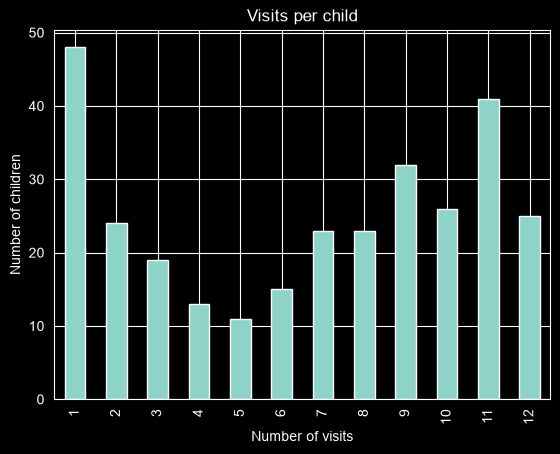

In [4]:
visits = df.groupby("id").size()
print(f"{df['id'].nunique()} children, {len(df)} measurements")
print(f"Visits per child: median {visits.median()}, min {visits.min()}, max {visits.max()}")

visits.value_counts().sort_index().plot(kind="bar")
plt.xlabel("Number of visits"); plt.ylabel("Number of children")
plt.title("Visits per child"); plt.show()

Unbalanced data because every child didn't had the same number of visits. Unbalanced data can be handled by MIXED-EFFECTS MODELS (standard method for cohort studies).

### Spaghetti plot

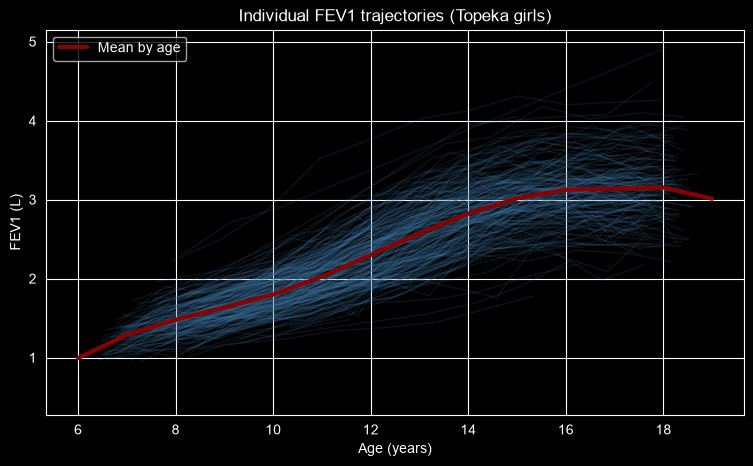

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for _, g in df.groupby("id"):
    ax.plot(g["age"], g["fev1"], color="steelblue", alpha=0.15, linewidth=1)

mean_curve = df.groupby(df["age"].round())["fev1"].mean()
ax.plot(mean_curve.index, mean_curve.values, color="darkred", linewidth=3, label="Mean by age")

ax.set_xlabel("Age (years)"); ax.set_ylabel("FEV1 (L)")
ax.set_title("Individual FEV1 trajectories (Topeka girls)"); ax.legend(); plt.show()

### A few children up close

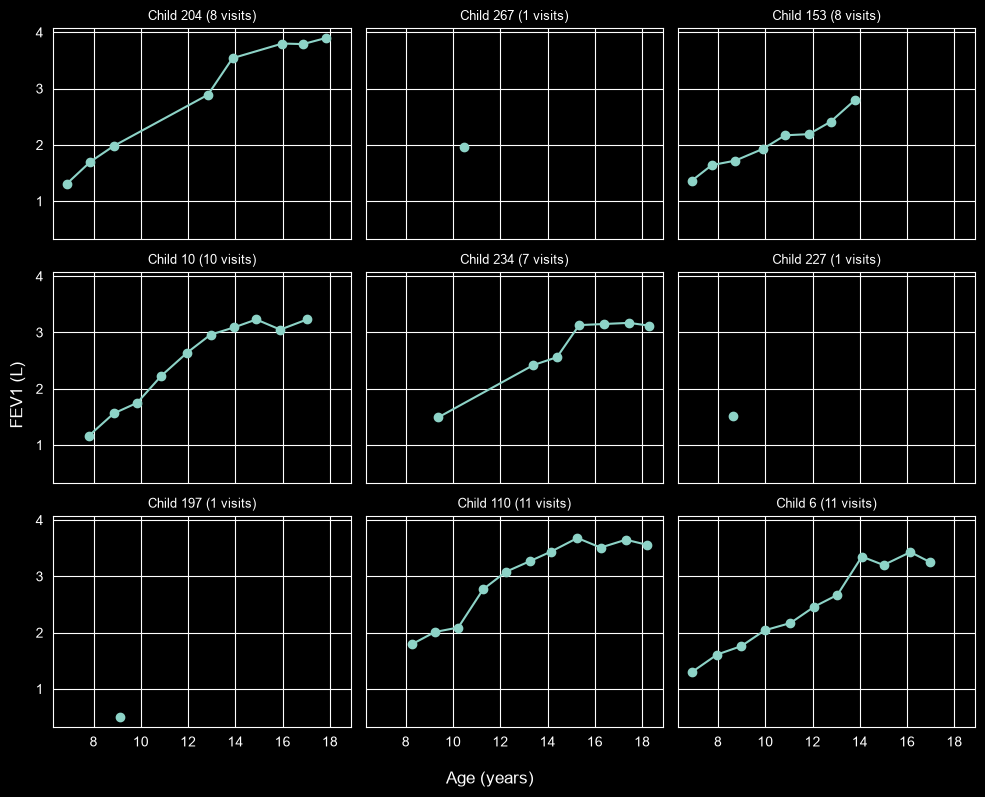

In [6]:
sample_ids = df["id"].drop_duplicates().sample(9, random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharex=True, sharey=True)
for ax, child_id in zip(axes.flat, sample_ids):
    g = df[df["id"] == child_id]
    ax.plot(g["age"], g["fev1"], "o-")
    ax.set_title(f"Child {child_id} ({len(g)} visits)", fontsize=9)

fig.supxlabel("Age (years)"); fig.supylabel("FEV1 (L)")
plt.tight_layout(); plt.show()

Investigating results as height predicts FEV1 better

In [7]:
# How unusual is each measurement compared with other children of similar height?
df["height_bin"] = (df["height"] * 20).round() / 20        # 5 cm bins
grp = df.groupby("height_bin")["log_fev1"]
df["z_height"] = (df["log_fev1"] - grp.transform("mean")) / grp.transform("std")

# The most extreme measurements
print(df.loc[df["z_height"].abs() > 3.5,
             ["id", "age", "height", "fev1", "z_height"]].sort_values("z_height"))

# Look at child 197 specifically
print(df[df["id"] == 197][["id", "age", "height", "fev1", "z_height"]])

       id      age  height      fev1  z_height
1483  197   9.1362    1.22  0.499999 -5.904525
1729  246  14.5791    1.62  1.759993 -3.797119
909   118  13.2019    1.59  1.779994 -3.707133
84     10  14.8857    1.46  3.229993  3.531050
86     10  17.0294    1.46  3.229993  3.531050
       id     age  height      fev1  z_height
1483  197  9.1362    1.22  0.499999 -5.904525


In [8]:
for child_id in [10, 118, 246]:
    print(f"\n--- Child {child_id} ---")
    print(df[df["id"] == child_id][["age", "height", "fev1", "z_height"]].round(2))


--- Child 10 ---
          age  height  fev1  z_height
77   7.790000    1.13  1.16     -0.07
78   8.850000    1.17  1.56      2.27
79   9.850000    1.25  1.75      1.93
80  10.870000    1.34  2.23      2.62
81  11.960000    1.42  2.64      3.38
82  12.950000    1.45  2.96      2.87
83  13.950000    1.45  3.09      3.20
84  14.890000    1.46  3.23      3.53
85  15.900000    1.46  3.05      3.10
86  17.030001    1.46  3.23      3.53

--- Child 118 ---
           age  height  fev1  z_height
903   7.090000    1.25  0.96     -3.28
904   8.050000    1.30  1.52     -0.04
905   9.050000    1.36  1.49     -1.28
906  10.180000    1.42  1.72     -0.44
907  11.160000    1.47  1.92     -0.38
908  12.170000    1.53  2.00     -1.89
909  13.200000    1.59  1.78     -3.71
910  14.100000    1.66  2.49     -1.72
911  15.200000    1.69  3.01     -0.67
912  16.129999    1.70  3.29      0.09
913  17.120001    1.71  3.15     -0.28
914  18.059999    1.71  3.29      0.09

--- Child 246 ---
            age  he

In [10]:
df["suspect"] = False
df.loc[[1483, 909, 1729], "suspect"] = True    # child 197; child 118 at 13.2; child 246 at 14.6
print(df.loc[df["suspect"], ["id", "age", "height", "fev1", "z_height"]])

       id      age  height      fev1  z_height
909   118  13.2019    1.59  1.779994 -3.707133
1483  197   9.1362    1.22  0.499999 -5.904525
1729  246  14.5791    1.62  1.759993 -3.797119


3 measurements were flagged as implausible (one FEV1 of exactly 0.5 L with z = −5.9; two visits from child 10 with identical height and FEV1 two years apart). Main analyses include them; sensitivity analyses exclude them.

In [11]:
df["prev_fev1"] = df.groupby("id")["fev1"].shift(1)    # FEV1 at the previous visit
df["next_fev1"] = df.groupby("id")["fev1"].shift(-1)   # FEV1 at the next visit

dips = df[
    (df["fev1"] < df["prev_fev1"] - 0.2) &             # at least 0.2 L below the previous visit
    (df["next_fev1"] > df["fev1"] + 0.3)                # and the next visit recovers
]
print(f"{len(dips)} dip-and-recover visits")
print(dips[["id", "age", "prev_fev1", "fev1", "next_fev1"]].round(2))

16 dip-and-recover visits
       id    age  prev_fev1  fev1  next_fev1
13      2  16.67       3.17  2.52       3.11
185    27  11.01       2.23  1.98       2.64
213    30  11.73       2.04  1.52       2.56
438    60  17.00       3.13  2.46       3.03
463    64  14.54       2.91  2.63       3.50
472    66  12.73       2.79  2.40       3.28
654    85  16.85       2.52  2.09       2.53
689    90  15.29       2.96  2.76       3.08
909   118  13.20       2.00  1.78       2.49
932   120  11.61       1.91  1.53       2.31
1039  134  14.96       3.28  2.92       3.27
1283  163  11.42       1.94  1.69       2.19
1577  214  14.24       3.16  2.86       3.17
1579  214  16.24       3.17  2.82       3.40
1729  246  14.58       2.06  1.76       2.59
1810  263   9.84       1.68  1.45       2.26


In [12]:
df["suspect"] = False
df["suspect_reason"] = ""

df.loc[dips.index, "suspect"] = True
df.loc[dips.index, "suspect_reason"] = "dip_and_recover"

df.loc[1483, "suspect"] = True
df.loc[1483, "suspect_reason"] = "implausible_low (z=-5.9)"

print(df["suspect"].sum(), "flagged measurements")
print(df["suspect_reason"].value_counts())

df.to_csv("../data/fev1_clean.csv", index=False)   # save for the next notebook

17 flagged measurements
suspect_reason
                            1977
dip_and_recover               16
implausible_low (z=-5.9)       1
Name: count, dtype: int64


### Age vs height

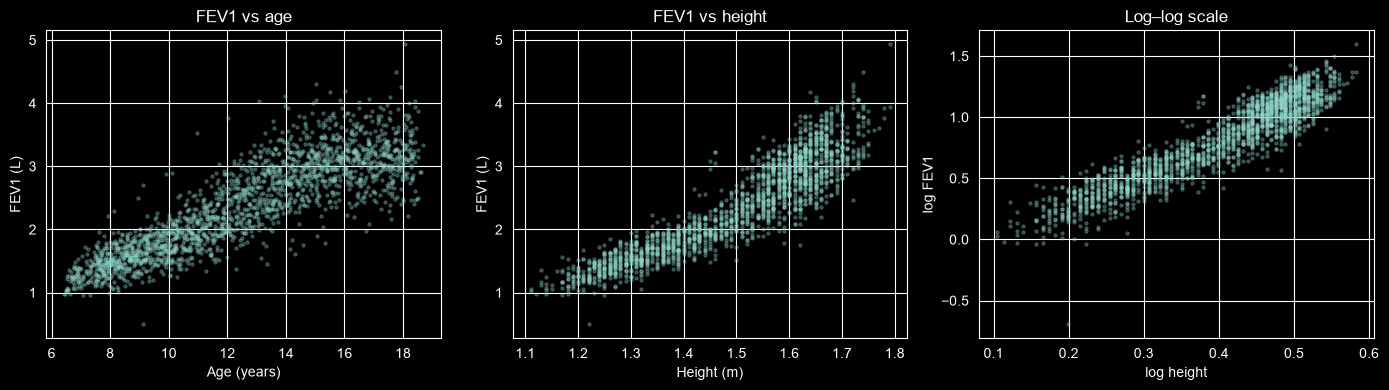

            age  height   fev1  log_fev1
age       1.000   0.888  0.865     0.872
height    0.888   1.000  0.909     0.931
fev1      0.865   0.909  1.000     0.986
log_fev1  0.872   0.931  0.986     1.000
FEV1 ≈ 0.71 × height^2.90


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(df["age"], df["fev1"], s=5, alpha=0.3)
axes[0].set(xlabel="Age (years)", ylabel="FEV1 (L)", title="FEV1 vs age")
axes[1].scatter(df["height"], df["fev1"], s=5, alpha=0.3)
axes[1].set(xlabel="Height (m)", ylabel="FEV1 (L)", title="FEV1 vs height")
axes[2].scatter(np.log(df["height"]), df["log_fev1"], s=5, alpha=0.3)
axes[2].set(xlabel="log height", ylabel="log FEV1", title="Log–log scale")
plt.tight_layout(); plt.show()

print(df[["age", "height", "fev1", "log_fev1"]].corr().round(3))

b, log_a = np.polyfit(np.log(df["height"]), df["log_fev1"], 1)
print(f"FEV1 ≈ {np.exp(log_a):.2f} × height^{b:.2f}")

## Exploration summary

**Data:** 300 girls, 1994 spirometry measurements, ages ~6–18. No empty cells;
missingness takes the form of missing visits. Visits per child range from 1 to 12
and are bimodal: 48 girls have a single visit, while many have 9–12.

**Growth pattern:** FEV1 rises from ~1 L at age 6 to ~3 L at 15, then plateaus.
The timing of the plateau differs between girls (some still growing at 18), and
growth spurts occur at different ages.

**Predictors:** height correlates more strongly with FEV1 than age (r = 0.91 vs 0.87).
On the log–log scale the relationship is linear with constant spread:
FEV1 ≈ 0.71 × height^2.90, close to the volume–length scaling of ~3.
Age and height are highly correlated (r = 0.89), but age carries extra information:
a short 17-year-old has higher FEV1 than younger girls of the same height.

**Data quality:** 17 measurements flagged: one implausible value (z = −5.9) and
16 "dip-and-recover" visits consistent with poor-effort spirometry (~1% of
checkable visits). Flags are kept with reasons; flagged visits will be excluded
in a sensitivity analysis.

**Implications for modelling:**
1. Model log FEV1, which gives a linear relationship and constant variance.
2. Use log height as the main predictor, plus a flexible (spline) term for age
   to capture maturation and the plateau.
3. Include a random intercept and random slope per girl, since girls differ in
   both level and growth rate.
4. Use a mixed model so all 300 girls contribute, including single-visit girls;
   this is valid if missingness is MAR.
5. Repeat the main analysis without flagged visits (sensitivity analysis).
6. Always split train/test by girl, never by row.